# Phase 2 — Transformer Fine-tuning

## Goal

Fine-tune a compact pretrained BERT model for three-class Roman Urdu sentiment.
`google/bert_uncased_L-2_H-128_A-2` is a small two-layer BERT checkpoint chosen so
the experiment is reproducible on a CPU-only laptop. Its English WordPiece
vocabulary can split Latin-script Roman Urdu, but this limitation is discussed in
the final comparison.

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"

for folder in [IMAGES, MODELS, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(PROJECT_ROOT / ".cache" / "huggingface")
print("Project folder:", PROJECT_ROOT)

Project folder: E:\AssDS\Project


In [2]:
import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "google/bert_uncased_L-2_H-128_A-2"
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
print("Device:", DEVICE)
print("Checkpoint:", MODEL_NAME)

Device: cpu
Checkpoint: google/bert_uncased_L-2_H-128_A-2


## 1. Load data and create validation data from training rows

In [3]:
train_df = pd.read_csv(DATA / "train.csv")
test_df = pd.read_csv(DATA / "test.csv")

fit_df, validation_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_df["label"],
)
fit_df = fit_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)

print("Fit rows:", len(fit_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

Fit rows: 13253
Validation rows: 2339
Test rows: 3898


## 2. Download the tokenizer and pretrained BERT weights

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={0: "Negative", 1: "Neutral", 2: "Positive"},
    label2id={"Negative": 0, "Neutral": 1, "Positive": 2},
).to(DEVICE)

print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Example tokens:", tokenizer.tokenize("yeh film bohat achi hai"))

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 4386307
Example tokens: ['ye', '##h', 'film', 'bo', '##hat', 'ac', '##hi', 'hai']


## 3. Tokenize sentences into BERT inputs

In [5]:
MAX_LENGTH = 64


class TransformerDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["model_text"].fillna("").tolist()
        self.labels = dataframe["label"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        encoded = tokenizer(
            self.texts[index],
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )
        item = {key: value.squeeze(0) for key, value in encoded.items()}
        item["labels"] = torch.tensor(self.labels[index], dtype=torch.long)
        return item


BATCH_SIZE = 64
fit_loader = DataLoader(TransformerDataset(fit_df), batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(TransformerDataset(validation_df), batch_size=BATCH_SIZE)
test_loader = DataLoader(TransformerDataset(test_df), batch_size=BATCH_SIZE)

example = next(iter(fit_loader))
print({key: value.shape for key, value in example.items()})

{'input_ids': torch.Size([64, 64]), 'token_type_ids': torch.Size([64, 64]), 'attention_mask': torch.Size([64, 64]), 'labels': torch.Size([64])}


## 4. Fine-tune BERT with class-weighted loss

In [6]:
class_counts = fit_df["label"].value_counts().sort_index().values
class_weights = len(fit_df) / (3 * class_counts)
loss_function = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5)


def forward_batch(batch):
    labels = batch.pop("labels").to(DEVICE)
    inputs = {key: value.to(DEVICE) for key, value in batch.items()}
    logits = model(**inputs).logits
    return logits, labels


def evaluate(loader):
    model.eval()
    losses = []
    predictions = []
    actual = []

    with torch.no_grad():
        for batch in loader:
            logits, labels = forward_batch(batch)
            losses.append(loss_function(logits, labels).item())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            actual.extend(labels.cpu().tolist())

    return np.mean(losses), f1_score(actual, predictions, average="macro"), predictions, actual


history = []
best_state = None
best_validation_f1 = -1
training_start = time.perf_counter()

for epoch in range(1, 3):
    model.train()
    training_losses = []

    for batch in fit_loader:
        optimizer.zero_grad()
        logits, labels = forward_batch(batch)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        training_losses.append(loss.item())

    validation_loss, validation_f1, _, _ = evaluate(validation_loader)
    row = {
        "epoch": epoch,
        "train_loss": float(np.mean(training_losses)),
        "validation_loss": float(validation_loss),
        "validation_macro_f1": float(validation_f1),
    }
    history.append(row)
    print(row)

    if validation_f1 > best_validation_f1:
        best_validation_f1 = validation_f1
        best_state = copy.deepcopy(model.state_dict())

training_seconds = time.perf_counter() - training_start
model.load_state_dict(best_state)
print(f"Training time: {training_seconds:.1f} seconds")

{'epoch': 1, 'train_loss': 1.0705823204838312, 'validation_loss': 1.0467393801018998, 'validation_macro_f1': 0.4613549062059256}


{'epoch': 2, 'train_loss': 1.0323663437022612, 'validation_loss': 1.014065463800688, 'validation_macro_f1': 0.49745159963468794}
Training time: 96.8 seconds


## 5. Evaluate once on the same untouched test set

In [7]:
test_loss, test_macro_f1, test_predictions, test_actual = evaluate(test_loader)
test_accuracy = accuracy_score(test_actual, test_predictions)
test_weighted_f1 = f1_score(test_actual, test_predictions, average="weighted")

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")
print(
    classification_report(
        test_actual,
        test_predictions,
        labels=[0, 1, 2],
        target_names=LABEL_NAMES,
        digits=4,
        zero_division=0,
    )
)

Test loss: 1.0014
Test accuracy: 0.5223
Test macro-F1: 0.5141
              precision    recall  f1-score   support

    Negative     0.4458    0.4317    0.4386      1047
     Neutral     0.6704    0.4973    0.5710      1689
    Positive     0.4562    0.6403    0.5328      1162

    accuracy                         0.5223      3898
   macro avg     0.5241    0.5231    0.5141      3898
weighted avg     0.5462    0.5223    0.5241      3898



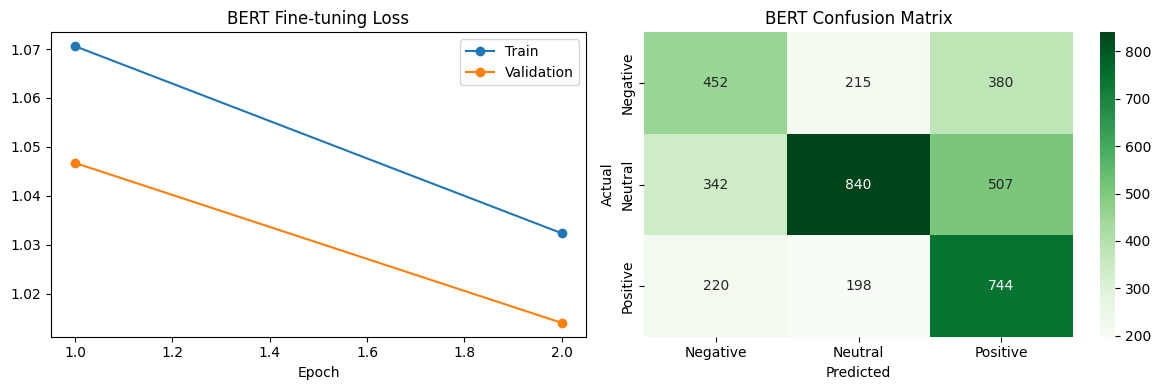

In [8]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation")
axes[0].set_title("BERT Fine-tuning Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

matrix = confusion_matrix(test_actual, test_predictions, labels=[0, 1, 2])
sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[1])
axes[1].set_title("BERT Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(IMAGES / "08_bert_training_and_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Save model state, settings, predictions, and metrics

In [9]:
torch.save(model.state_dict(), MODELS / "bert_tiny_sentiment.pt")

configuration = {
    "base_model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "labels": {"0": "Negative", "1": "Neutral", "2": "Positive"},
}
(MODELS / "bert_tiny_config.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")

pd.DataFrame(history).to_csv(RESULTS / "bert_training_history.csv", index=False)
pd.DataFrame(
    [{
        "model": "BERT Tiny",
        "accuracy": test_accuracy,
        "macro_f1": test_macro_f1,
        "weighted_f1": test_weighted_f1,
        "fit_seconds": training_seconds,
    }]
).to_csv(RESULTS / "bert_test_results.csv", index=False)

bert_predictions = test_df[["sentence", "sentiment", "label"]].copy()
bert_predictions["BERT Tiny"] = test_predictions
bert_predictions.to_csv(RESULTS / "bert_test_predictions.csv", index=False)

print("Saved BERT artifacts and results.")

Saved BERT artifacts and results.


## Conclusion

This is a genuine fine-tuning experiment: pretrained BERT weights are updated for
the sentiment labels. The checkpoint is intentionally tiny for CPU reproducibility;
a larger multilingual transformer is a sensible future improvement when a GPU is
available.